# The measured game

A learned model chooses **what to measure next**; the GPU decides **what is faster**. Per load $l$, a bootstrap
ensemble of $K$ LightGBM models gives a mean and a spread for every unmeasured design $d$, and the frontier is ranked
by an upper confidence bound

$$
\text{UCB}_l(d) = \mu_l(d) + \kappa\, \sigma_l(d) - J_l(\text{incumbent}), \qquad
\mu_l = \tfrac1K \textstyle\sum_k f_k(d),\ \ \sigma_l = \operatorname{sd}_k f_k(d).
$$

A design **binds** for load $l$ when its build identity has at least two confirm-grade samples $g_1, \dots, g_n$
next to the incumbent with

$$
\bar g > m, \qquad \min_i g_i > 0 .
$$

This notebook runs the loop on a synthetic problem with one planted 2% gain
(decoder 11 on the 16-token load) and many look-alikes. The configuration below
requires three confirmation rounds. A design nominated for multiple loads is
measured once, and each load/build identity contributes at most one observation
per round. The trace and figure show when the rule is met. This repeat-and-margin
rule is a heuristic, not a confidence-interval test; selection can still bias the
reported gain above the planted truth.

**Evidence and execution:** Synthetic seeded objective exercising the public search loop; no measured GPU speedup.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
import itertools, math, random
LOADS = ("m1", "m16", "m32")
SPACE = {"cutoff": [8, 17], "tile": [64, 128, 256], "stages": [2, 3, 4], "unroll": [1, 2, 4], "decoder": list(range(16))}
INC = {"cutoff": 17, "tile": 128, "stages": 3, "unroll": 2, "decoder": 0}
REACH = xc.ReachMap(loads={"m1": 1, "m16": 16, "m32": 32}, cutoff_field="cutoff",
                    fields={"large": ("tile", "stages"), "small": ("unroll",), "all": ("decoder",)})
rng = random.Random(0)
def truth(d, l):
    g = 1.0
    if l == "m16" and d["decoder"] == 11: g *= 1.02
    if l == "m32" and REACH.build_of(l, d) == "large": g *= 1 + 0.003 * (d["stages"] - 3) - 0.004 * abs(math.log2(d["tile"] / 128))
    if l == "m1": g *= 1 - 0.01 * abs(d["unroll"] - 2)
    return g
measure = lambda ds, grade: [{l: truth(d, l) * math.exp(rng.gauss(0, 0.010 if grade == "screen" else 0.003)) for l in LOADS} for d in ds]
featurize = lambda d, c: [d["cutoff"], d["tile"], d["stages"], d["unroll"]] + xc.bits(d["decoder"], 4)
allD = [dict(zip(SPACE, v)) for v in itertools.product(*SPACE.values())]
frontier = lambda h: [d for d in allD if repr(sorted(d.items())) not in {repr(sorted(x["design"].items())) for x in h}]
game = xc.Game(loads=LOADS, reach=REACH, incumbent=INC, frontier=frontier, featurize=featurize,
               compile=lambda ds: [{"ok": True} for _ in ds], measure=measure, per_load=6, compile_n=18, screen_n=12,
               margin=0.008, min_samples=3)
seed = [INC] + rng.sample(allD, 40)
for d, l in zip(seed, measure(seed, "screen")): game.history.append({"design": d, "loads": l, "weight": 1.0})
trace = []
for rnd in range(1, 9):
    rep = game.round(); trace.append(rep); print(rnd, rep)

1 {'frontier': 823, 'compiled': 18, 'screened': 12, 'confirmed': 4, 'bound': {}}


2 {'frontier': 811, 'compiled': 18, 'screened': 12, 'confirmed': 8, 'bound': {}}


3 {'frontier': 799, 'compiled': 18, 'screened': 12, 'confirmed': 9, 'bound': {'m16': 2.16}}


4 {'frontier': 787, 'compiled': 18, 'screened': 12, 'confirmed': 8, 'bound': {'m16': 2.2}}


5 {'frontier': 775, 'compiled': 18, 'screened': 12, 'confirmed': 12, 'bound': {'m16': 2.21}}


6 {'frontier': 763, 'compiled': 18, 'screened': 12, 'confirmed': 10, 'bound': {'m16': 2.43}}


7 {'frontier': 751, 'compiled': 18, 'screened': 12, 'confirmed': 8, 'bound': {'m16': 2.43}}


8 {'frontier': 739, 'compiled': 18, 'screened': 12, 'confirmed': 7, 'bound': {'m16': 2.43}}


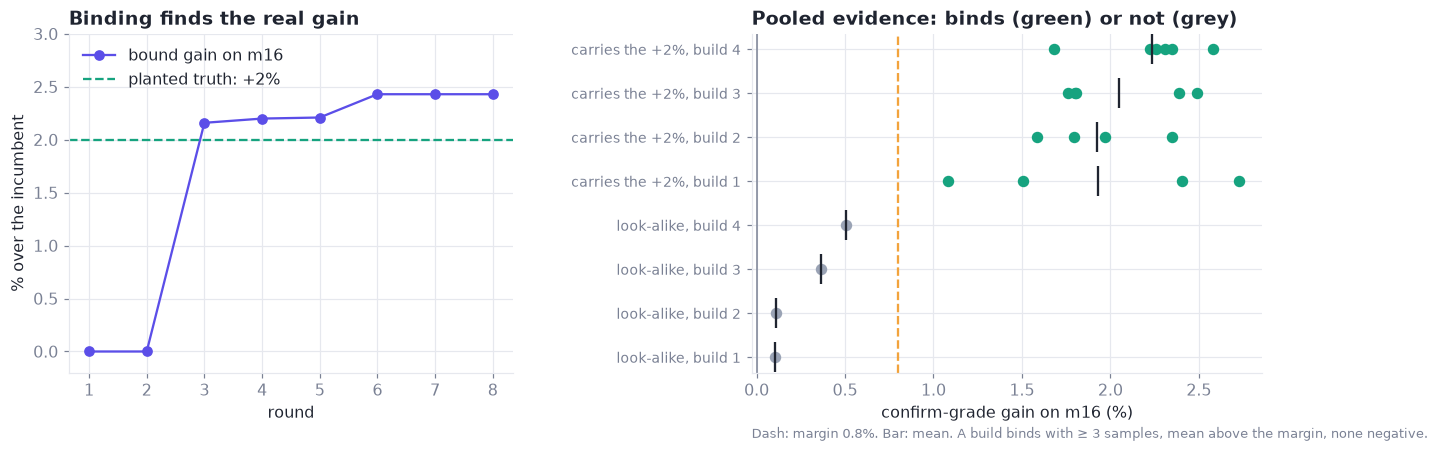

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.15], "wspace": 0.5})
axes[0].plot(range(1, 9), [t["bound"].get("m16", 0) for t in trace], "o-", color=C["ours"], label="bound gain on m16")
axes[0].axhline(2.0, color=C["good"], ls="--", label="planted truth: +2%"); axes[0].set_ylim(-0.2, 3)
axes[0].set_xlabel("round"); axes[0].set_ylabel("% over the incumbent"); axes[0].legend(); axes[0].set_title("Binding finds the real gain")
ev = game.evidence.rows.get("m16", {})
real = sorted([k for k in ev if ev[k]["design"]["decoder"] == 11], key=lambda k: -len(ev[k]["gains"]))[:4]
fake = sorted([k for k in ev if ev[k]["design"]["decoder"] != 11], key=lambda k: -max(ev[k]["gains"]))[:4]
rows = [(k, "look-alike") for k in fake[::-1]] + [(k, "carries the +2%") for k in real[::-1]]
for i, (k, kind) in enumerate(rows):
    g = np.array(ev[k]["gains"]) * 100
    ok = len(g) >= 3 and g.mean() > 0.8 and g.min() > 0
    axes[1].scatter(g, np.full(len(g), i), color=C["good"] if ok else C["ref"], s=42, zorder=3)
    axes[1].scatter([g.mean()], [i], marker="|", s=380, color=INK, zorder=4)
axes[1].axvline(0.8, color=C["accent"], ls="--"); axes[1].axvline(0, color=MUTED, lw=1)
axes[1].set_yticks(range(len(rows)), [f"{kind}, build {i % 4 + 1}" for i, (_, kind) in enumerate(rows)], fontsize=9)
axes[1].set_xlabel("confirm-grade gain on m16 (%)"); axes[1].set_title("Pooled evidence: binds (green) or not (grey)")
note(axes[1], "Dash: margin 0.8%. Bar: mean. A build binds with ≥ 3 samples, mean above the margin, none negative.")
save(fig, "game_binding"); plt.show()

[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)